# TeleData · Отток клиентов
**Итоговый проект • вариант 7 • user1**  
Задача — ранжировать клиентов для ограниченной кампании удержания. Ниже результаты выполнения, а не пример ожидаемого вывода. Код моделей и очистки един для DAG и отчёта (`churn7_core.py`).

## 0. Паспорт варианта

In [1]:
import hashlib
from pathlib import Path

STUDENT = "user1"          # логин в стеке (не менять)
N = 7                      # номер по журналу

# параметры варианта (формулы — в README_project.md)
TEST_SIZE = {0: 0.20, 1: 0.25, 2: 0.30}[N % 3]
EXTRA_MODEL = ["HistGradientBoostingClassifier", "SVC(probability=True)",
               "GaussianNB", "ExtraTreesClassifier"][N % 4]
PRIMARY_METRIC = "roc_auc" if N % 2 == 0 else "average_precision"
P_FLAKY = round(0.25 + 0.10 * (N % 3), 2)
GATE_MARGIN = 0.01

EXPERIMENT = f"user1_p{N}_churn"
MODEL_NAME = f"user1_p{N}_model"
DAG_ID = f"user1_p{N}_churn"

print(f"N={N} | тест={TEST_SIZE} | доп.модель={EXTRA_MODEL} | метрика={PRIMARY_METRIC}")
print(f"вероятность сбоя DAG p={P_FLAKY} | порог ворот=чемпион+{GATE_MARGIN}")

raw_path = Path(f"customers_{N}.csv")
assert raw_path.exists(), f"сначала сгенерируйте датасет: python make_dataset.py --student {N}"
PASSPORT = hashlib.sha256(f"rudn2026:{N}:".encode() + raw_path.read_bytes()).hexdigest()[:16]
print("PASSPORT:", PASSPORT)

N=7 | тест=0.25 | доп.модель=ExtraTreesClassifier | метрика=average_precision
вероятность сбоя DAG p=0.35 | порог ворот=чемпион+0.01
PASSPORT: dbe598ae595cf3d2


## 1. Проверка сервисов
Среда сохранённого прогона: IPython/Jupyter kernel, PostgreSQL 16, Airflow 2.11 с LocalExecutor, MLflow 3.16.1. Вместо Docker и RustFS использован локальный S3-совместимый тестовый сервер Moto; это проверка S3 API, но не установки Docker. В Compose адреса сервисов и бакеты те же.

In [2]:
import io, os, sys, time, uuid, hashlib, json, ast
from pathlib import Path
from contextlib import closing
import boto3, mlflow.sklearn, psycopg2, requests
import pandas as pd, numpy as np
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../dags').resolve()))
sys.path.insert(0, str(Path('../../../dags').resolve()))
import churn7_core as core
from make_dataset import generate
# В Docker DAG-и примонтированы в ../../dags; при запуске из checkout — в ../../../dags.

ART = Path('evidence'); ART.mkdir(exist_ok=True)
BASE = 'http://airflow-webserver:8080/api/v1'
auth = ('student', 'student')
def api(method, path, **kw):
    r = requests.request(method, BASE+path, auth=auth, timeout=20, **kw)
    r.raise_for_status(); return r.json()
def airflow(path): return api('GET',path)
s3c=core.s3(); s3c.head_bucket(Bucket=STUDENT)
client=mlflow.MlflowClient(); client.search_experiments(max_results=1)
with closing(core.pg()) as con, con.cursor() as cur:
    cur.execute('SELECT version()'); print(cur.fetchone()[0])
health=airflow('/health'); print('Airflow:', health['scheduler']['status'], health['metadatabase']['status'])
assert health['scheduler']['status']==health['metadatabase']['status']=='healthy'
print('S3: бакет доступен; MLflow: API экспериментов доступен.')

PostgreSQL 16.2 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 10.2.1 20210130 (Red Hat 10.2.1-11), 64-bit
Airflow: healthy healthy
S3: бакет доступен; MLflow: API экспериментов доступен.


## 2. Сырые данные → S3

In [3]:
df = generate(N)
assert df.to_csv(index=False).encode() == raw_path.read_bytes(), 'CSV не совпал с генератором'
raw_key=f'project/{N}/raw/{raw_path.name}'
core.put(raw_key, raw_path.read_bytes()); assert core.read(raw_key).read()==raw_path.read_bytes()
print(raw_key, df.shape, 'доля оттока', (df.churn=='Yes').mean())
print('Повторы ID:',df.customer_id.duplicated().sum(), '| пропуски сумм:',df.total_charges.isna().sum(),
      '| счета > 118:', df.monthly_charges.gt(118).sum())
display(df.head(3)); display(pd.crosstab(df.cancellation_request,df.churn,normalize='index'))

project/7/raw/customers_7.csv (7815, 20) доля оттока 0.2674344209852847
Повторы ID: 15 | пропуски сумм: 234 | счета > 118: 12


,customer_id,age,region,partner,dependents,tenure_months,contract,internet_service,phone_service,online_security,tech_support,streaming_tv,paperless_billing,payment_method,monthly_charges,total_charges,support_calls,referral_code,cancellation_request,churn
0,CUST-04764,73,South,No,No,23,Month-to-month,DSL,Yes,No,No,No,Yes,Electronic check,48.96,1027.99,1,P-T-N,No,No
1,CUST-02924,60,South,Yes,Yes,44,Month-to-month,No,Yes,No internet,No internet,No internet,Yes,Electronic check,20.77,850.65,3,X-U-P,Yes,Yes
2,CUST-02517,26,South,No,No,15,Month-to-month,DSL,Yes,No,No,Yes,No,Electronic check,74.00,1052.13,1,G-N-C,No,No


churn,No,Yes
cancellation_request,,
No,0.865417,0.134583
Yes,0.070444,0.929556


Сначала удаляем повторные ID, затем записи с невозможной месячной платой (>118 — верхняя граница генератора). Отсутствующие накопленные платежи оцениваем как стаж × месячный платёж. `cancellation_request` с высокой точностью выдаёт класс: заявка появляется **после решения об уходе**. В генераторе она строится из `churn`, поэтому исключена до разбиения. Регион и реферальный код сгенерированы как шум; ID хранится только для выдачи.

## 3. Очищенная витрина и три SQL-вопроса

In [4]:
d = core.clean(df)
assert d.customer_id.is_unique and not d.isna().any().any()
cols = list(d.columns)
types = ['text PRIMARY KEY' if k=='customer_id' else 'integer' if pd.api.types.is_integer_dtype(d[k]) else
         'double precision' if pd.api.types.is_numeric_dtype(d[k]) else 'text' for k in cols]
with closing(core.pg()) as con, con, con.cursor() as cur:
    cur.execute('CREATE SCHEMA IF NOT EXISTS user1_project')
    cur.execute('CREATE TABLE IF NOT EXISTS user1_project.customers ('+', '.join(f'{k} {t}' for k,t in zip(cols,types))+')')
    cur.execute('TRUNCATE user1_project.customers')
    cur.copy_expert('COPY user1_project.customers ('+','.join(cols)+') FROM STDIN WITH CSV',io.StringIO(d.to_csv(index=False,header=False)))
    cur.execute('SELECT COUNT(*), SUM(churn) FROM user1_project.customers'); print('Клиентов, ушедших:',cur.fetchone())
def query(sql):
    with closing(core.pg()) as con, con.cursor() as cur:
        cur.execute(sql); return pd.DataFrame(cur.fetchall(),columns=[x.name for x in cur.description])

Клиентов, ушедших: (7788, 2085)


In [5]:
contracts=query('SELECT contract, count(*) AS n, avg(churn)::float AS churn_rate\nFROM user1_project.customers GROUP BY contract ORDER BY churn_rate DESC'); display(contracts)

,contract,n,churn_rate
0,Month-to-month,4338,0.323421
1,One year,1975,0.259241
2,Two year,1475,0.115254


Помесячные контракты лидируют по доле оттока: около 32% против 12% у двухлетних.

In [6]:
segments=query('SELECT internet_service,payment_method,count(*) AS n,avg(churn)::float AS churn_rate\nFROM user1_project.customers GROUP BY 1,2 ORDER BY churn_rate DESC,1,2 LIMIT 5'); display(segments)
print('Наивысшая доля:', *segments.iloc[0,:2], f"{segments.churn_rate[0]:.1%}")

,internet_service,payment_method,n,churn_rate
0,Fiber optic,Electronic check,1181,0.377646
1,Fiber optic,Credit card (automatic),786,0.312977
2,Fiber optic,Bank transfer (automatic),860,0.298837
3,Fiber optic,Mailed check,903,0.292359
4,No,Electronic check,506,0.262846


Наивысшая доля: Fiber optic Electronic check 37.8%


Это рейтинг по доле, а не по количеству; размер сегмента указан рядом, чтобы не принять маленькую группу за основной источник потерь.

In [7]:
calls=query('SELECT churn,count(*) AS n,avg(support_calls)::float AS mean_calls\nFROM user1_project.customers GROUP BY churn ORDER BY churn'); display(calls)

,churn,n,mean_calls
0,0,5703,1.453095
1,1,2085,1.656115


Среднее у ушедших выше (1,66 против 1,45). По числу звонков нельзя установить, что именно поддержка вызвала уход.

## 4. Восемь графиков EDA

In [8]:
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.figsize':(7.2,3.6),'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
color='#167674'; accent='#c46538'
def save(fig,name,folder='eda'):
    fig.tight_layout(); buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=115,bbox_inches='tight'); plt.close(fig)
    dest=ART/f'{name}.png'; dest.write_bytes(buf.getvalue())
    if folder=='eda': core.put(f'project/{N}/eda/{name}.png',buf.getvalue())
    display(Image(data=buf.getvalue())); return dest

def rate(col,title,name):
    fig,ax=plt.subplots(); vals=d.groupby(col,observed=True).churn.mean().sort_values(); vals.plot.barh(ax=ax,color=color)
    ax.set(title=title,ylabel='',xlabel='Доля ушедших'); ax.xaxis.set_major_formatter(PercentFormatter(1)); save(fig,name)

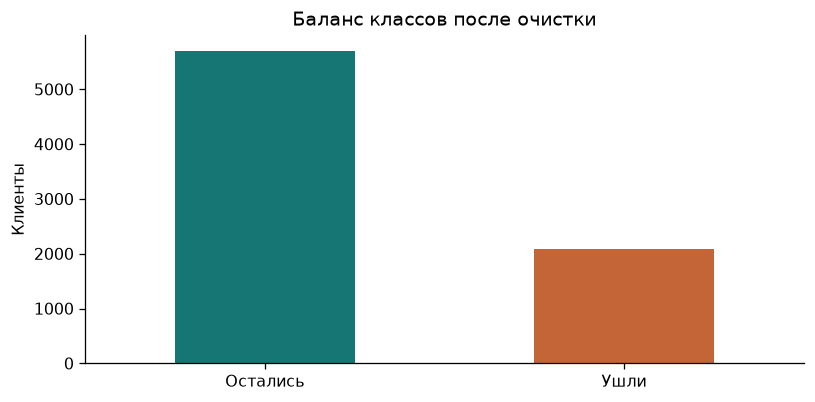

PosixPath('evidence/01_balance.png')

In [9]:
fig,ax=plt.subplots(); d.churn.value_counts().sort_index().set_axis(['Остались','Ушли']).plot.bar(ax=ax,color=[color,accent],rot=0)
ax.set(title='Баланс классов после очистки',ylabel='Клиенты'); save(fig,'01_balance')

**Вывод.** Ушли 26,8% клиентов. У классификатора, который всех объявляет оставшимися, высокая accuracy, но он не найдёт ни одного ушедшего.

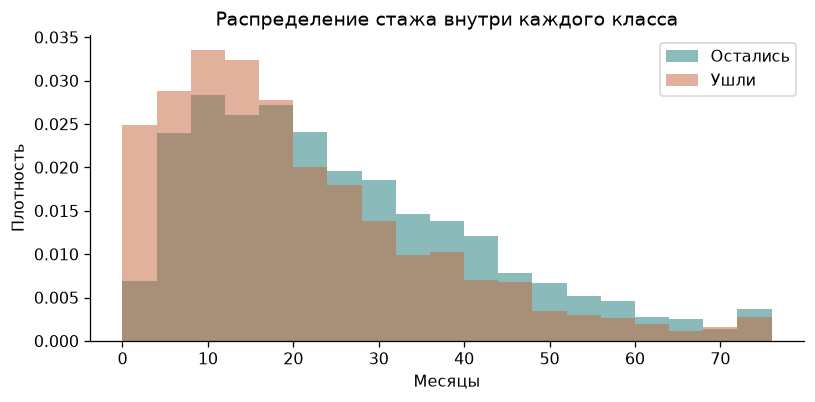

PosixPath('evidence/02_tenure_dist.png')

In [10]:
fig,ax=plt.subplots()
for label,group in d.groupby('churn'):
    ax.hist(group.tenure_months,bins=np.arange(0,77,4),density=True,alpha=.5,label=['Остались','Ушли'][label],color=[color,accent][label])
ax.legend(); ax.set(title='Распределение стажа внутри каждого класса',xlabel='Месяцы',ylabel='Плотность'); save(fig,'02_tenure_dist')

**Вывод.** У ушедших больше коротких историй: средний стаж около 20 месяцев, у оставшихся — около 25. Нормировка позволяет сравнить классы разного размера.

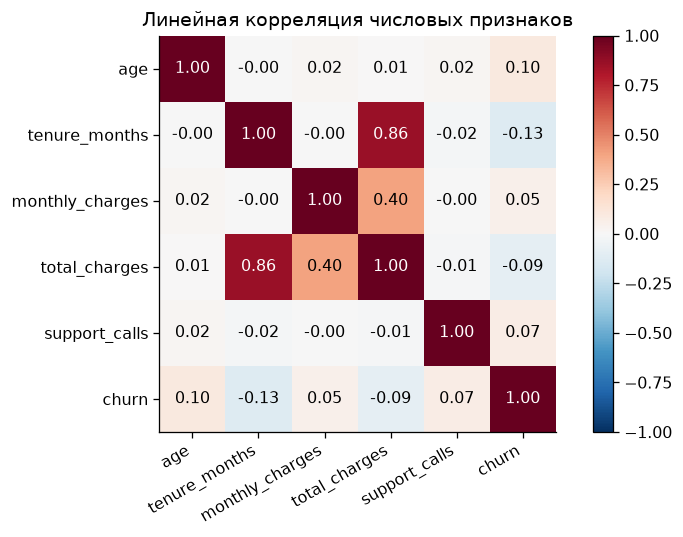

PosixPath('evidence/03_corr.png')

In [11]:
m=d.select_dtypes('number').corr(); fig,ax=plt.subplots(figsize=(7.3,4.8)); im=ax.imshow(m,cmap='RdBu_r',vmin=-1,vmax=1)
ax.set_xticks(range(len(m)),m.columns,rotation=30,ha='right'); ax.set_yticks(range(len(m)),m.columns)
for i in range(len(m)):
    for j in range(len(m)): ax.text(j,i,f'{m.iloc[i,j]:.2f}',ha='center',va='center',color='white' if abs(m.iloc[i,j])>.7 else 'black')
ax.set_title('Линейная корреляция числовых признаков'); fig.colorbar(im,ax=ax); save(fig,'03_corr')

**Вывод.** Стаж и накопленная сумма сильно связаны (r ≈ 0,86). Слабая корреляция с целевой меткой не исключает нелинейной зависимости.

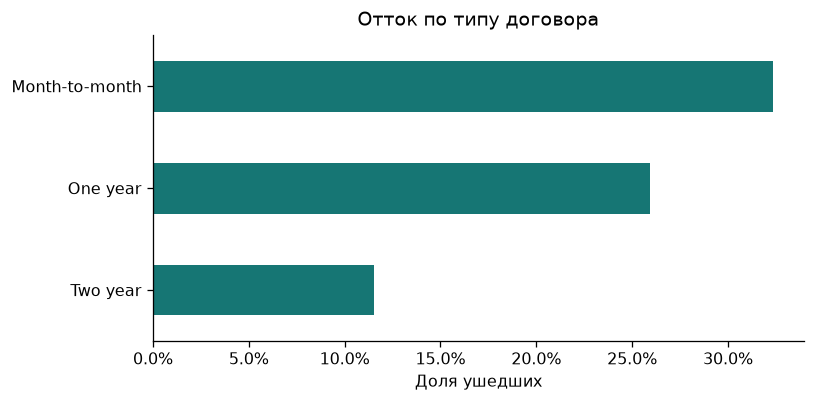

In [12]:
rate('contract','Отток по типу договора','04_contract')

**Вывод.** Двухлетний договор связан с меньшим риском, чем помесячный; это различие полезно для сегментации.

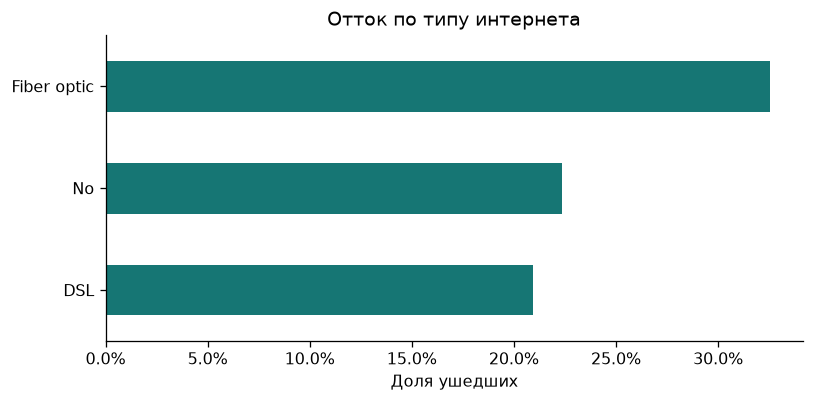

In [13]:
rate('internet_service','Отток по типу интернета','05_internet')

**Вывод.** У Fiber optic отток около 32,5%, у DSL — около 21%. Групповые средние не доказывают эффект технологии.

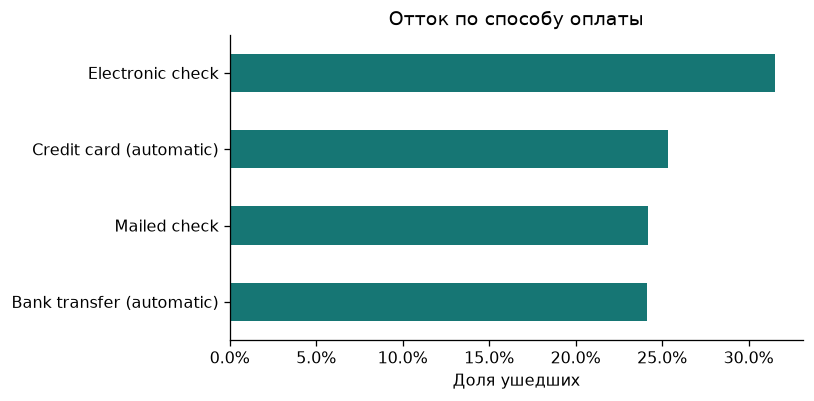

In [14]:
rate('payment_method','Отток по способу оплаты','06_payment')

**Вывод.** Electronic check выделяется долей около 31,6%; три остальных способа близки между собой.

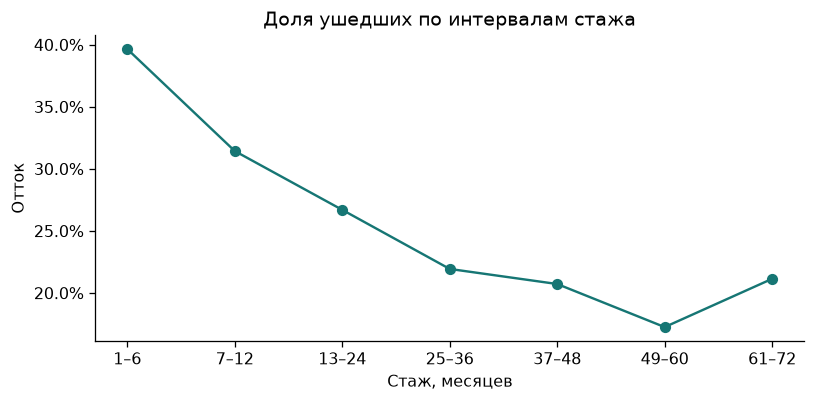

PosixPath('evidence/07_tenure_rate.png')

In [15]:
bands=pd.cut(d.tenure_months,[0,6,12,24,36,48,60,72]); rates=d.groupby(bands,observed=True).churn.mean()
fig,ax=plt.subplots(); ax.plot(range(len(rates)),rates.values,'o-',color=color); ax.set_xticks(range(len(rates)),['1–6','7–12','13–24','25–36','37–48','49–60','61–72']); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set(title='Доля ушедших по интервалам стажа',xlabel='Стаж, месяцев',ylabel='Отток'); save(fig,'07_tenure_rate')

**Вывод.** Самая высокая доля — в первые шесть месяцев (около 40%). Зависимость не монотонна: у группы 61–72 месяца доля снова повышается.

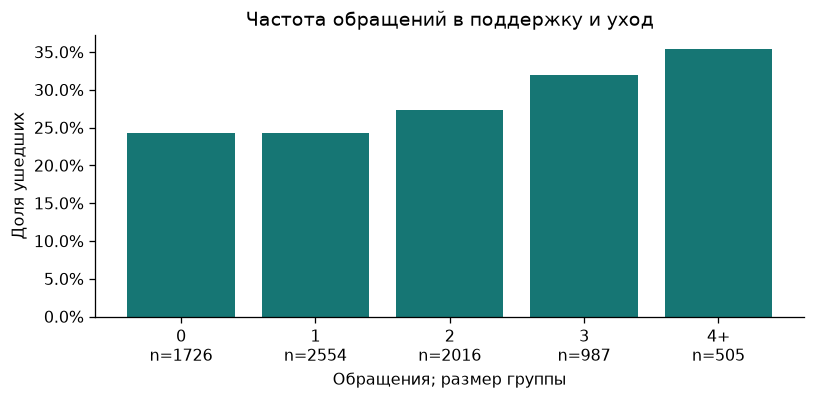

PosixPath('evidence/08_support.png')

In [16]:
g=d.groupby(d.support_calls.clip(upper=4)).churn.agg(['mean','size']);fig,ax=plt.subplots();ax.bar(range(len(g)),g['mean'],color=color)
ax.set_xticks(range(len(g)),[f'{x if x<4 else "4+"}\nn={n}' for x,n in g['size'].items()]);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set(title='Частота обращений в поддержку и уход',xlabel='Обращения; размер группы',ylabel='Доля ушедших');save(fig,'08_support')

**Вывод.** При 0–1 звонке доля около 24%, при трёх уже 32%. Редкие большие значения объединены, чтобы не интерпретировать шум малых групп.

## 5. Сопоставимое обучение и MLflow
Стратификация сохраняет долю ухода. Кодировщик и скейлер обучаются только на train; на test применяются без дообучения. В соответствии с заданием выбор из сетки идёт по AP на test. Это делает оценку победителя оптимистичной: для внедрения нужен отдельный контрольный период.

In [17]:
train,test=core.split(d); assert set(train.customer_id).isdisjoint(test.customer_id)
print('Train / test:',len(train),len(test),'| доли ухода:',train.churn.mean(),test.churn.mean()); print(core.GRID)

Train / test: 5841 1947 | доли ухода: 0.2677623694572847 0.26759116589625065
{'LogisticRegression': ('C', [0.01, 0.5, 10]), 'RandomForest': ('max_depth', [4, 8, 14]), 'DecisionTree': ('max_depth', [2, 5, 10]), 'KNN': ('n_neighbors', [5, 25, 75]), 'ExtraTrees': ('max_depth', [5, 10, 18])}


In [18]:
batch=uuid.uuid4().hex[:10]; grid=[]
for family,(parameter,values) in core.GRID.items():
    for value in values:
        grid.append(core.fit_run(family,value,train,test,'grid',batch))

🏃 View run LogisticRegression_0.01 at: http://mlflow:5000/#/experiments/1/runs/8ecb6d0853a14ccdb0ab84259687d59d
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run LogisticRegression_0.5 at: http://mlflow:5000/#/experiments/1/runs/512f0b87a52445a5816ac4edc911edb3
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run LogisticRegression_10 at: http://mlflow:5000/#/experiments/1/runs/665d14432b8a4a678798b368b2506a90
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run RandomForest_4 at: http://mlflow:5000/#/experiments/1/runs/cc3bfe72585147aaa81d5356f257a7bc
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run RandomForest_8 at: http://mlflow:5000/#/experiments/1/runs/261ccdaddce34ab7853f9d475ce40f02
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run RandomForest_14 at: http://mlflow:5000/#/experiments/1/runs/75e177d1460d42b081358683f4764e9c
🧪 View experiment at: http://mlflow:5000/#/experiments/1


... (5 outputs left out)

🏃 View run KNN_75 at: http://mlflow:5000/#/experiments/1/runs/84db230613504c91a758a9c3ebc412d7
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run ExtraTrees_5 at: http://mlflow:5000/#/experiments/1/runs/66a73fe6cc2349898302986c86e4df12
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run ExtraTrees_10 at: http://mlflow:5000/#/experiments/1/runs/d30e20011eff489f8ac30179f3ebafea
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run ExtraTrees_18 at: http://mlflow:5000/#/experiments/1/runs/ec52091820ec4da594cb5857f795f13f
🧪 View experiment at: http://mlflow:5000/#/experiments/1


In [19]:
runs_df=mlflow.search_runs(experiment_names=[EXPERIMENT],filter_string=f"tags.batch = '{batch}'",order_by=['metrics.average_precision DESC'])
cols=['tags.mlflow.runName','params.family','metrics.average_precision','metrics.roc_auc','run_id'];display(runs_df[cols].reset_index(drop=True))
leader=max(grid,key=lambda x:x[PRIMARY_METRIC]); tuned={k:max((r for r in grid if r['family']==k), key=lambda x:x[PRIMARY_METRIC])['value'] for k in core.GRID}
print('Победитель сетки:',leader)

,tags.mlflow.runName,params.family,metrics.average_precision,metrics.roc_auc,run_id
0,RandomForest_8,RandomForest,0.591273,0.782144,261ccdaddce34ab7853f9d475ce40f02
1,RandomForest_14,RandomForest,0.571382,0.770174,75e177d1460d42b081358683f4764e9c
2,RandomForest_4,RandomForest,0.560527,0.757143,cc3bfe72585147aaa81d5356f257a7bc
3,DecisionTree_5,DecisionTree,0.520852,0.754698,5262757575d54699a61252c0c45ccc0f
4,ExtraTrees_10,ExtraTrees,0.513735,0.737753,d30e20011eff489f8ac30179f3ebafea
5,KNN_75,KNN,0.507208,0.738609,84db230613504c91a758a9c3ebc412d7
6,ExtraTrees_5,ExtraTrees,0.498779,0.726658,66a73fe6cc2349898302986c86e4df12
7,ExtraTrees_18,ExtraTrees,0.468519,0.715670,ec52091820ec4da594cb5857f795f13f
8,KNN_25,KNN,0.466564,0.712174,bf5016c99b02402ab3355745810d1e60
9,DecisionTree_10,DecisionTree,0.434186,0.703682,33246ec75799480782d8a57a45b093a6


Победитель сетки: {'family': 'RandomForest', 'value': 8, 'run_id': '261ccdaddce34ab7853f9d475ce40f02', 'uri': 'models:/m-7adb8f3eb88746b59b023fdc9f3228f3', 'roc_auc': 0.7821443281207516, 'average_precision': 0.59127294155064}


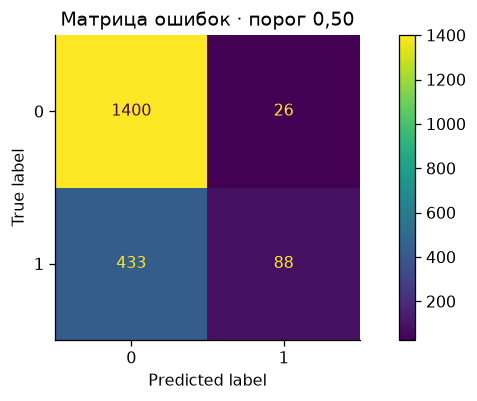

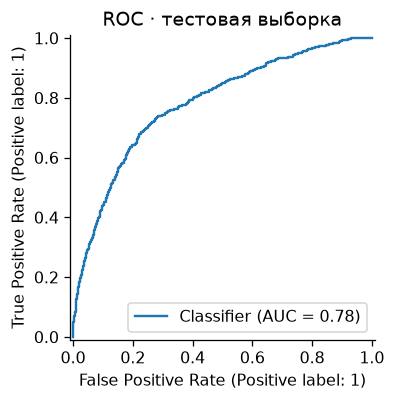

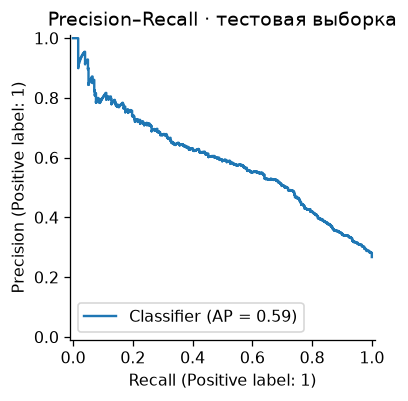

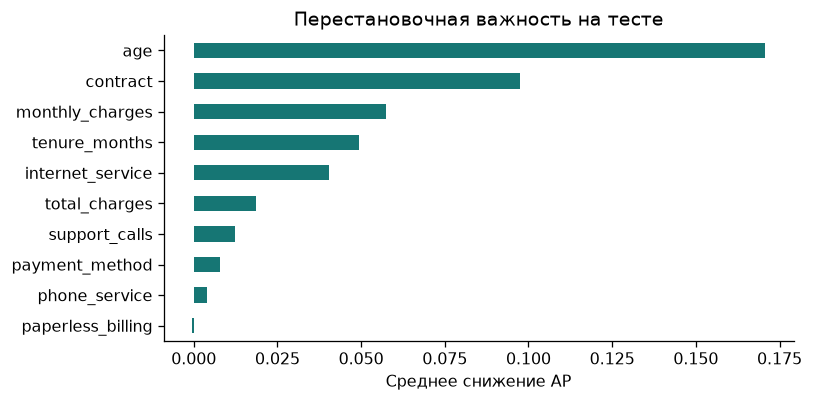

🏃 View run RandomForest_8 at: http://mlflow:5000/#/experiments/1/runs/261ccdaddce34ab7853f9d475ce40f02
🧪 View experiment at: http://mlflow:5000/#/experiments/1


In [20]:
from sklearn.metrics import ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay
from sklearn.inspection import permutation_importance
best_model=mlflow.sklearn.load_model(leader['uri']); X=core.features(test); score=best_model.predict_proba(X)[:,1]
with mlflow.start_run(run_id=leader['run_id']):
    for name,chart,title in [('confusion',ConfusionMatrixDisplay.from_predictions(test.churn,score>=.5),'Матрица ошибок · порог 0,50'),
                            ('roc',RocCurveDisplay.from_predictions(test.churn,score),'ROC · тестовая выборка'),
                            ('pr',PrecisionRecallDisplay.from_predictions(test.churn,score),'Precision–Recall · тестовая выборка')]:
        chart.ax_.set_title(title); mlflow.log_artifact(str(save(chart.figure_,name,'models')), 'diagnostics')
    imp=permutation_importance(best_model,X,test.churn,scoring='average_precision',random_state=N,n_repeats=4,n_jobs=1)
    importance=pd.Series(imp.importances_mean,index=X.columns).sort_values(); fig,ax=plt.subplots(); importance.tail(10).plot.barh(ax=ax,color=color)
    ax.set(title='Перестановочная важность на тесте',xlabel='Среднее снижение AP'); mlflow.log_artifact(str(save(fig,'importance','models')), 'diagnostics')

## 6. Airflow и ворота качества
Сначала конвейер выпускает первую версию с простой конфигурацией (малая глубина/сильная регуляризация). Затем проверяем лидера сетки и отдельно обученного претендента. Наконец DAG повторяет обучение с выбранными параметрами. При отказе ворот ничего не перерегистрируем: следующий шаг применяет действующего чемпиона. Между задачами передаются только ссылки и небольшие результаты.

In [21]:
path=f'/dags/{DAG_ID}/dagRuns'
api('PATCH',f'/dags/{DAG_ID}',json={'is_paused':False})
def run_dag(run_id,params):
    # Фиксированное имя baseline позволяет повторно прочитать первый выпуск при Run All.
    url=f'{path}/{run_id}'; response=requests.get(BASE+url,auth=auth,timeout=15)
    if response.status_code==404: api('POST',path,json={'dag_run_id':run_id,'conf':{'params_by_family':params}})
    else: response.raise_for_status()
    deadline=time.monotonic()+1200
    while time.monotonic()<deadline:
        result=airflow(url)
        if result['state']=='failed': raise RuntimeError(f'Запуск {run_id} неуспешен; проверьте журнал задач')
        if result['state']=='success': return result
        time.sleep(3)
    raise TimeoutError(run_id)
def xc(run_id,task):
    value=airflow(f'{path}/{run_id}/taskInstances/{task}/xcomEntries/return_value')['value']
    if not isinstance(value,str): return value
    try: return ast.literal_eval(value)
    except (ValueError,SyntaxError): return value
def attempts(run): return airflow(f"{path}/{run['dag_run_id']}/taskInstances/load_raw")['try_number']
base_run=run_dag('manual__p7_baseline',{k:v[1][0] for k,v in core.GRID.items()}); base_id=base_run['dag_run_id']
print('Первый DAG:',base_id,base_run['state'],'| load_raw:',attempts(base_run),'| ворота:',xc(base_id,'quality_gate'))

Первый DAG: manual__p7_baseline success | load_raw: 1 | ворота: {'previous': None, 'threshold': None, 'candidate': 0.5605266073826237, 'promote': True}


In [22]:
decisions=[]
def evaluate(label,candidate):
    decision=core.gate(candidate); version=core.register(candidate,decision)
    decisions.append({'этап':label,**decision,'версия':version}); display(pd.DataFrame(decisions))
evaluate('Лидер сетки',leader)
# Новый гиперпараметр, вне сетки лидера: проверка, а не автоматический релиз.
alternate={'LogisticRegression':1e-5,'RandomForest':2,'DecisionTree':1,'ExtraTrees':2,'KNN':301}[leader['family']]
challenger=core.fit_run(leader['family'],alternate,train,test,'challenger',batch); evaluate('Претендент',challenger)

Registered model 'user1_p7_model' already exists. Creating a new version of this model...
2026/11/19 20:15:18 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: user1_p7_model, version 2


Created version '2' of model 'user1_p7_model'.


,этап,previous,threshold,candidate,promote,версия
0,Лидер сетки,0.560527,0.570527,0.591273,True,2


🏃 View run RandomForest_2 at: http://mlflow:5000/#/experiments/1/runs/8c410c1e6ff147f7b609e56af5642682
🧪 View experiment at: http://mlflow:5000/#/experiments/1


,этап,previous,threshold,candidate,promote,версия
0,Лидер сетки,0.560527,0.570527,0.591273,True,2
1,Претендент,0.591273,0.601273,0.520992,False,2


In [23]:
history=[base_run]
for i in range(1,17):
    run=run_dag(f'manual__p7_{batch}_{i:02d}',tuned); history.append(run)
    print(run['dag_run_id'],run['state'],'| попыток load_raw:',attempts(run),'| ворота:',xc(run['dag_run_id'],'quality_gate'))
    if attempts(run)>=2: break
assert attempts(history[-1])>=2,'Ни одного случайного сбоя в последних 16 запусках'
last_id=history[-1]['dag_run_id']; tasks=airflow(f'{path}/{last_id}/taskInstances')['task_instances']
display(pd.DataFrame(tasks)[['task_id','state','try_number','start_date','end_date']].sort_values('start_date'))

manual__p7_0fdbb84482_01 success | попыток load_raw: 2 | ворота: {'previous': 0.59127294155064, 'threshold': 0.60127294155064, 'candidate': 0.59127294155064, 'promote': False}


,task_id,state,try_number,start_date,end_date
7,load_raw,success,2,2026-11-19T20:15:52.724206+00:00,2026-11-19T20:15:53.678735+00:00
8,prepare,success,1,2026-11-19T20:15:54.645045+00:00,2026-11-19T20:15:57.354469+00:00
9,train_LogisticRegression,success,1,2026-11-19T20:15:58.003843+00:00,2026-11-19T20:16:05.958535+00:00
10,train_RandomForest,success,1,2026-11-19T20:15:58.005790+00:00,2026-11-19T20:16:06.523118+00:00
1,train_DecisionTree,success,1,2026-11-19T20:16:07.982210+00:00,2026-11-19T20:16:15.999500+00:00
0,train_KNN,success,1,2026-11-19T20:16:08.127825+00:00,2026-11-19T20:16:15.754391+00:00
2,train_ExtraTrees,success,1,2026-11-19T20:16:17.063852+00:00,2026-11-19T20:16:24.719098+00:00
3,select_best,success,1,2026-11-19T20:16:25.158022+00:00,2026-11-19T20:16:25.490133+00:00
4,quality_gate,success,1,2026-11-19T20:16:26.246656+00:00,2026-11-19T20:16:28.102088+00:00
5,register_champion,success,1,2026-11-19T20:16:28.476085+00:00,2026-11-19T20:16:30.108409+00:00


In [24]:
key=xc(last_id,'top_risk'); risk=pd.read_csv(core.read(key)); risk.to_csv(ART/'top_risk.csv',index=False)
pg_top=query(f"SELECT customer_id, probability FROM user1_project.top_risk WHERE ds='{history[-1]['execution_date'][:10]}' ORDER BY probability DESC,customer_id")
assert len(risk)==len(pg_top)==100 and risk.customer_id.is_unique and risk.customer_id.equals(pg_top.customer_id) and np.allclose(risk.probability,pg_top.probability)
print('Две копии выдачи совпали:',key); display(risk.head(10))

Две копии выдачи совпали: project/7/2026-11-19/manual__p7_0fdbb84482_01/top_risk.csv


,customer_id,probability
0,CUST-05298,0.743482
1,CUST-02740,0.707829
2,CUST-01697,0.691586
3,CUST-07468,0.680825
4,CUST-02781,0.673689
5,CUST-07382,0.670321
6,CUST-07185,0.659382
7,CUST-06015,0.657110
8,CUST-01200,0.649624
9,CUST-04302,0.644342


## 7. Что получилось и кого удерживать

In [25]:
v=client.get_model_version_by_alias(MODEL_NAME,'champion'); last_gate=xc(last_id,'quality_gate')
hit=test.set_index('customer_id').loc[risk.customer_id].churn.mean(); sg=segments.iloc[0]
print(f"1. Лучший результат у {leader['family']} ({core.GRID[leader['family']][0]}={leader['value']}): AP {leader[PRIMARY_METRIC]:.4f}, ROC AUC {leader['roc_auc']:.4f}. Базовый AP ≈ {test.churn.mean():.4f}.")
print('Наиболее чувствительный для победителя признак по permutation importance:',importance.idxmax())
print('2. cancellation_request — следствие решения об уходе; генератор вычисляет заявку из класса. На момент прогноза её нет.')
print(f'3. Последнему load_raw потребовалось {attempts(history[-1])} попыток. Простой cron без retry потерял бы этот запуск до следующего расписания.')
print(f'4. Итоговая версия: {v.version}. В последних воротах: {last_gate}. Равенство не оправдывает новую версию.')
print(f'5. При бюджете 100 звонков приоритет у верхних 100 по скору, а не у всего сегмента {sg.internet_service} / {sg.payment_method}. В этом сегменте доля ухода {sg.churn_rate:.1%}. В тестовом top-100 ушли {hit:.0%}, по всему тесту {test.churn.mean():.1%}.')
print('Это качество ранжирования, не оценка эффекта звонка: инкрементальное удержание надо проверять A/B-тестом.')

1. Лучший результат у RandomForest (max_depth=8): AP 0.5913, ROC AUC 0.7821. Базовый AP ≈ 0.2676.
Наиболее чувствительный для победителя признак по permutation importance: age
2. cancellation_request — следствие решения об уходе; генератор вычисляет заявку из класса. На момент прогноза её нет.


3. Последнему load_raw потребовалось 2 попыток. Простой cron без retry потерял бы этот запуск до следующего расписания.
4. Итоговая версия: 2. В последних воротах: {'previous': 0.59127294155064, 'threshold': 0.60127294155064, 'candidate': 0.59127294155064, 'promote': False}. Равенство не оправдывает новую версию.
5. При бюджете 100 звонков приоритет у верхних 100 по скору, а не у всего сегмента Fiber optic / Electronic check. В этом сегменте доля ухода 37.8%. В тестовом top-100 ушли 77%, по всему тесту 26.8%.
Это качество ранжирования, не оценка эффекта звонка: инкрементальное удержание надо проверять A/B-тестом.


Деревья могут разделять возраст и стаж на интервалы и учитывать сочетания признаков, например тип интернета и платёж. Поэтому ансамбль способен уловить эффекты, которые линейная модель без взаимодействий пропускает. Перестановочная важность показывает зависимость качества от признака, а не причинный эффект вмешательства.

## 8. Самопроверка из шаблона

In [26]:
import hashlib
from pathlib import Path

results = []
def ok(name, cond, detail=""):
    results.append((name, bool(cond), detail))

# 1) паспорт совпадает с файлом датасета
raw = Path(f"customers_{N}.csv")
if raw.exists():
    h = hashlib.sha256(f"rudn2026:{N}:".encode() + raw.read_bytes()).hexdigest()[:16]
    ok("Паспорт датасета", h == PASSPORT, h)
else:
    ok("Паспорт датасета", False, "файл датасета не найден")

# 2) сырые данные и графики EDA в S3
s3c = boto3.client("s3", endpoint_url=os.environ["S3_ENDPOINT_URL"],
                   aws_access_key_id=STUDENT, aws_secret_access_key=os.environ["S3_PASSWORD"])
def keys(prefix):
    return [o["Key"] for o in s3c.list_objects_v2(Bucket=STUDENT, Prefix=prefix).get("Contents", [])]
ok("Сырой CSV в S3", any(k.endswith(f"customers_{N}.csv") for k in keys(f"project/{N}/raw/")))
ok("≥8 графиков EDA в S3", len(keys(f"project/{N}/eda/")) >= 8, f'{len(keys(f"project/{N}/eda/"))} шт')

# 3) MLflow: запуски и чемпион
runs_df = mlflow.search_runs(experiment_names=[EXPERIMENT])
ok("≥15 запусков в эксперименте", len(runs_df) >= 15, f"{len(runs_df)} запусков")
ok("≥5 разных моделей", runs_df["tags.mlflow.runName"].str.split("_").str[0].nunique() >= 5)
try:
    mv = mlflow.MlflowClient().get_model_version_by_alias(MODEL_NAME, "champion")
    ok("Чемпион в реестре", True, f"версия {mv.version}")
except Exception:
    ok("Чемпион в реестре", False, "метка @champion не найдена")

# 4) Airflow: последний запуск зелёный и были повторы
try:
    last = airflow(f"/dags/{DAG_ID}/dagRuns?order_by=-execution_date&limit=1")["dag_runs"][0]
    ti = airflow(f"/dags/{DAG_ID}/dagRuns/{last['dag_run_id']}/taskInstances")["task_instances"]
    ok("Последний запуск DAG успешен", last["state"] == "success", last["execution_date"])
    retries = next(t["try_number"] for t in ti if t["task_id"] == "load_raw")
    ok("Показан повтор (try_number ≥ 2)", retries >= 2, f"попыток load_raw: {retries}")
    ok("top_risk сохранил CSV", any(k.endswith("top_risk.csv") for k in keys(f"project/{N}/")))
except Exception as e:
    ok("Airflow", False, str(e)[:80])

# 5) PostgreSQL: таблица top_risk не пустая
try:
    conn = psycopg2.connect(host="postgres", dbname="postgres", user="airflow", password="airflow")
    cnt = pd.read_sql(f'SELECT count(*) FROM user1_project.top_risk', conn).iloc[0, 0]
    conn.close()
    ok("top_risk в PostgreSQL", cnt >= 50, f"{cnt} строк")
except Exception as e:
    ok("top_risk в PostgreSQL", False, str(e)[:80])

print()
print("=" * 62)
n_ok = sum(1 for _, c, _ in results if c)
for name, cond, detail in results:
    print(f'  [{"OK" if cond else "FAIL"}] {name}' + (f' — {detail}' if detail else ""))
print("=" * 62)
print(f"ИТОГ: {n_ok}/{len(results)} проверок пройдено")
assert n_ok == len(results), "есть красные проверки — доработайте части проекта"


  [OK] Паспорт датасета — dbe598ae595cf3d2
  [OK] Сырой CSV в S3
  [OK] ≥8 графиков EDA в S3 — 8 шт
  [OK] ≥15 запусков в эксперименте — 26 запусков
  [OK] ≥5 разных моделей
  [OK] Чемпион в реестре — версия 2
  [OK] Последний запуск DAG успешен — 2026-11-19T20:15:20.130931+00:00
  [OK] Показан повтор (try_number ≥ 2) — попыток load_raw: 2
  [OK] top_risk сохранил CSV
  [OK] top_risk в PostgreSQL — 100 строк
ИТОГ: 10/10 проверок пройдено


/tmp/ipykernel_3041/1676273429.py:48: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cnt = pd.read_sql(f'SELECT count(*) FROM user1_project.top_risk', conn).iloc[0, 0]
